# 02 — Préparation des données Weld DB (version corrigée après audit)

Cette version remplace le notebook `ai_prepared` audité le 2026-10-08. Elle applique les décisions de `specs/spec.md` (le code réutilisable est dans `weld_prep.py`). Le notebook **ne convertit aucune unité, n'adopte pas de cible Charpy et n'entraîne pas de modèle final**.

### Correspondance audit → correction

| # | Point de l'audit | Correction ici |
|---|---|---|
| 1 | Imputation par médiane au lieu de l'itérative choisie | `FoldPreprocessor(method='iterative')` par défaut (paramètres de la spec), contrôle de convergence par pli. La médiane reste disponible comme **baseline de sensibilité** et est comparée (§11) |
| 2 | Doublons bruts conservés, contrôle incluant l'ID | Comparaison des 43 champs hors ID ; les 4 excédents (indices 393, 423, 425, 1434) sont écartés, leurs ID gardés comme alias |
| 3 | Groupes = profils d'entrées, séries partagées entre train et test | Groupes = **séries dérivées des identifiants** (règle du projet) + liens créés par les doublons → 47 groupes ; aucun groupe partagé entre plis |
| 4 | CV proposée sur des données déjà prétraitées | Plus aucune matrice prétraitée exportée ; le preprocessing est ajusté **dans chaque pli** (externe et interne) |
| 5 | Conversions d'unités non justifiées | **Aucune conversion**. Cellules suspectes → indisponibles (NaN), listées avec leur token brut et le motif |
| 6 | Azote, procédés, polarité réinterprétés | Azote annoté → indisponible dans la colonne principale, tokens tot/res conservés ; seuls les synonymes documentés `ShMA→MMA`, `SMA→SA` ; courant et polarité gardés tels quels + drapeaux d'incohérence |
| 7 | Température Charpy dans toutes les features | Schémas par tâche : traction **sans** température Charpy ; elle n'entre que dans E(T) (conditionnel) |
| 8 | Protocole Charpy 100/28 J non résolu | Table de **signatures par série** (hypothèses), pas de classement par valeur d'énergie isolée ; aucune tâche Charpy adoptée |
| 9 | Suppressions et traçabilité | `raw_row_id` stable, provenance par cellule, journal des alias, lignes non étiquetées et Gar&K PWHT manquant **conservées** dans la table maître avec drapeaux, éligibilité par cible, manifeste SHA-256 |

Les remplacements `<L → L/2` et intervalle → milieu sont des **approximations explicites**, pas des mesures ; leur statut et leurs bornes restent dans la provenance.

In [1]:
import json, platform, numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn, os
import weld_prep as W
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 160)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'font.size': 9})
RAW = 'welddb.data'; OUT = 'modeling'; os.makedirs(OUT, exist_ok=True)
print('SHA-256 brut :', W.sha256(RAW))
raw, prov, aliases, groups, master = W.build_master(RAW)
print(raw.shape, '->', master.shape)

SHA-256 brut : eb46df81a454c8e549187d87c67a6e72b88676f760e8688a782c832737676ac1


(1652, 45) -> (1652, 68)


## 1. Provenance par cellule

Chaque cellule numérique brute reçoit un **statut lexical** (`exact`, `missing_N`, `censored_left`, `interval`, `annotated`), des bornes et un éventuel **drapeau de revue d'unité**. `N` signifie « non rapporté », jamais zéro.

In [2]:
pd.crosstab(prov.column, prov.status).loc[lambda t: (t.drop(columns=['exact', 'missing_N'], errors='ignore').sum(axis=1) > 0)]

status,annotated,censored_left,exact,interval,missing_N
column,,,,,
Al_ppm,0,403,502,0,747
As_ppm,0,8,226,0,1418
B_ppm,0,419,85,0,1148
Co,0,21,108,0,1523
Cu,0,14,564,0,1074
Mo,0,2,791,0,859
N_ppm,59,0,1183,0,410
Nb_ppm,0,299,453,0,900
S,0,7,1641,0,4


### Cellules à unité douteuse — mises en quarantaine, non converties

Heuristiques non résolues de la spec : valeur positive < 1 dans une colonne ppm (Ti, Al, Sn, As, Sb), `<0.01` pour Ti/Al, `<5` pour V (colonne en wt%). Sans publication source, rien ne permet de certifier l'unité d'origine : la cellule devient **indisponible** dans la représentation numérique principale, le token brut est conservé. Les lignes ne sont pas supprimées.

In [3]:
rev = prov[prov.review_flag != ''].merge(raw[['raw_row_id', 'weld_id']], on='raw_row_id')
rev['series'] = rev.weld_id.map(lambda s: W.series_of(s)[0])
rev.groupby(['column', 'review_flag', 'series']).raw_token.agg(['size', lambda s: sorted(set(s))[:4]]).rename(columns={'<lambda_0>': 'tokens'})

size                        tokens
column review_flag               series                                            
Al_ppm censor_0.01_in_ppm_column PantK-1990        16                       [<0.01]
       positive_below_1ppm       EPRI-TR-101394    10  [0.004, 0.005, 0.013, 0.014]
As_ppm positive_below_1ppm       Ditt              20                       [0.003]
                                 Mart              70    [0.008, 0.01, 0.016, 0.03]
Sb_ppm positive_below_1ppm       Ditt              20                       [0.001]
                                 Mart              70                       [0.008]
Sn_ppm positive_below_1ppm       Ditt              20                       [0.002]
                                 Mart              70                [0.008, 0.009]
Ti_ppm censor_0.01_in_ppm_column PantK-1990        16                       [<0.01]
       positive_below_1ppm       Stil-TiB-1978      1                         [0.5]
V      censor_5_in_wt%_column    EvansLetter        9                          [<5]

### Représentation numérique principale (déterministe, aucun apprentissage)

| Statut | Valeur principale | Remarque |
|---|---|---|
| `exact` | valeur | zéros et extrêmes conservés |
| `censored_left` `<L`, sans drapeau | L/2 | approximation ; bornes [0, L] gardées (scénarios 0, L/√2 possibles) |
| `interval` `150-200` | 175 | approximation ; bornes gardées |
| `annotated` (azote `tot/res`, dureté `HvX`) | NaN | sémantique non établie ; tokens extraits à part, pas de mélange de protocoles de dureté |
| drapeau d'unité | NaN | quarantaine |
| `missing_N` | NaN | non rapporté |

In [4]:
master[['raw_row_id', 'weld_id', 'N_ppm', 'N_annotation', 'hardness_value', 'hardness_protocol']].query("N_annotation != ''").head(4)

,raw_row_id,weld_id,N_ppm,N_annotation,hardness_value,hardness_protocol
274,274,Evans-Al/CMn-1990-<5aw,NaN,tot=67;res=33,NaN,missing
275,275,Evans-Al/CMn-1990-<5awch1,NaN,tot=67;res=33,NaN,missing
276,276,Evans-Al/CMn-1990-<5awch2,NaN,tot=67;res=33,NaN,missing
277,277,Evans-Al/CMn-1990-<5aw,NaN,tot=67;res=33,NaN,missing


## 2. Déduplication

Règle de la spec : enregistrements identiques sur les **43 champs bruts hors identifiant** → le premier est conservé, les autres deviennent des alias. Des valeurs identiques ne prouvent pas qu'il s'agit du même essai physique ; c'est une déduplication **technique**, et le lien entre les séries concernées est conservé pour le groupage.

In [5]:
print(aliases.to_string(index=False))
dedup = master[~master.is_duplicate_excess].copy()
print('\nLignes après déduplication :', len(dedup))

 raw_row_id                weld_id  kept_raw_row_id         kept_weld_id
        393 Evans-Nb/Mn-1991-A<5aw              333 Evans-V/Mn-1991-A3aw
        423 Evans-Nb/Mn-1991-C<6aw              363 Evans-V/Mn-1991-C4aw
        425 Evans-Nb/Mn-1991-C<6ht              365 Evans-V/Mn-1991-C4ht
       1434            Ditt-iatch3             1418          Ditt-oatch3

Lignes après déduplication : 1648


## 3. Catégories et drapeaux

- `weld_process` = code d'origine avec **uniquement** les synonymes documentés (`ShMA→MMA`, `SMA→SA`). `GMAA`, `NGGMA`, `GTAA`, `SAA`, `NGSAW`, `TSA` restent distincts ; `weld_type_raw` garde le code d'origine.
- `ac_dc_raw` / `polarity_raw` gardés séparément, sans inférer « DC » pour un `+` sans type de courant. Ils ne font pas partie du schéma principal (spec : à tester séparément).
- Drapeaux : AC avec `+` (incohérence de métadonnée), polarité sans type de courant, somme de microstructure ≠ 100 %, PWHT manquant.

In [6]:
print(dedup.weld_process.value_counts().to_dict())
dedup[['flag_ac_with_polarity', 'flag_polarity_without_current_type', 'flag_micro_sum_not_100', 'flag_pwht_missing']].sum()

{'MMA': 1177, 'SA': 260, 'FCA': 87, 'TSA': 87, 'NGSAW': 18, 'NGGMA': 7, 'SAA': 4, 'GTAA': 4, 'GMAA': 4}


flag_ac_with_polarity                  4
flag_polarity_without_current_type    59
flag_micro_sum_not_100                 3
flag_pwht_missing                     13
dtype: int64

**PWHT manquant (13 lignes Gar&K).** Le code vérifie maintenant le motif réel (les deux champs PWHT sont `N`) au lieu d'un préfixe ; le suffixe `ht` est affiché pour contrôle. Ces lignes ne sont **pas supprimées** : elles restent dans la table maître et sont gérées par l'éligibilité des cohortes.

In [7]:
dedup.loc[dedup.flag_pwht_missing, ['raw_row_id', 'weld_id', 'yield_strength', 'elongation', 'reduction_area', f'n_unavail_{W.PRIMARY_SET}', 'in_strict13']]

,raw_row_id,weld_id,yield_strength,elongation,reduction_area,n_unavail_A1_13,in_strict13
1101,1101,Gar&K-1975-25mm-1ht,605.0,16.0,48.0,4,False
1103,1103,Gar&K-1975-25mm-2ht,665.0,29.0,66.0,4,False
1105,1105,Gar&K-1975-25mm-3ht,715.0,16.0,62.0,4,False
1107,1107,Gar&K-1975-25mm-4ht,784.0,17.0,64.0,4,False
1109,1109,Gar&K-1975-25mm-5ht,588.0,25.0,50.0,4,False
1111,1111,Gar&K-1975-25mm-6ht,604.0,30.0,48.0,4,False
1113,1113,Gar&K-1975-25mm-7ht,720.0,15.0,55.0,4,False
1115,1115,Gar&K-1975-25mm-8ht,740.0,21.0,60.0,4,False
1117,1117,Gar&K-1975-25mm-9ht,540.0,26.0,70.0,4,False
1119,1119,Gar&K-1975-25mm-10ht,580.0,30.0,66.0,4,False


## 4. Groupes de validation

Règle du projet : **série = préfixe d'identifiant jusqu'à l'année** ; familles explicites pour les identifiants non datés, lettres et rapports (`RR82011`, `EPRI-TR-101394`, `EvansLetter*`) ; préfixe non daté sinon ; identifiant exact en dernier recours. Les doublons relient ensuite leurs séries (`Evans-V/Mn-1991` + `Evans-Nb/Mn-1991`).

Ce sont des séries **dérivées des identifiants**, pas des publications validées. Les variantes d'orthographe `Ga&K`/`Gar&K` et `KocakPEv`/`KocakPREv` (aucune composition partagée constatée) restent séparées pour rester aligné sur la règle du projet ; `W.MERGE_NAME_VARIANTS=True` permet le test de sensibilité.

In [8]:
g = dedup.groupby('group').agg(n=('raw_row_id', 'size'), rule=('series_rule', 'first'), n_series=('series', 'nunique'))
print('Groupes :', len(g), '| règles :', g.rule.value_counts().to_dict())
print('Groupes formés par lien de doublon :', g[g.n_series > 1].index.tolist())
print('RC81033 -> groupes :', dedup.loc[dedup.weld_id == 'RC81033', 'group'].unique())
g.sort_values('n', ascending=False).T

Groupes : 47 | règles : {'prefix_year': 39, 'undated_prefix': 4, 'explicit_family': 3, 'exact_id_fallback': 1}
Groupes formés par lien de doublon : ['Evans-Nb/Mn-1991']
RC81033 -> groupes : <StringArray>
['RC81033']
Length: 1, dtype: str


group,EvansLetter,Evans-Nb/Mn-1991,Evans-AlTi-1994,Evans-StressRelief-1991,SvenGret-1990,Pat-1981,Mart,Evans-Ti/Mn-1992,Evans-Al/CMn-1990,Evans-Ni/CMn-1990,Evans-Cr/CMn-1989,Gar&K-1975,PantK-1990,RR82011,Evans-Ti/CMn-1992,Cunh-1982,Wolst-1974,EvHtIp1979,Evans-B/9Cr1Mo-1994,Icici&-1992,...,JorgeEtAl-1993,Hunt&-Di-1994,Evans-intpss-1978,Evans-AlEl9Cr1Mo-1994,EPRI-TR-101394,Kluket-CuMnB-1994,Evans-FelowH-1991,Es-Souni&-Cu/CMn-1990,Wats-1981,Ga&K-1975,Birmingham,Evans-Mn-1977,SurianEtAl-C-1991,Alekseev&-CMnNi-1991,Natsume-1990,RC81033,Sw&Rog-1973,Inag&-1966,Kik,KocakPEv-TiN-1994
n,156,117,114,110,96,79,70,60,59,58,58,56,54,46,40,38,32,32,32,30,...,16,16,16,13,12,12,12,12,12,10,9,8,8,7,4,4,4,2,2,1
rule,explicit_family,prefix_year,prefix_year,prefix_year,prefix_year,prefix_year,undated_prefix,prefix_year,prefix_year,prefix_year,prefix_year,prefix_year,prefix_year,explicit_family,prefix_year,prefix_year,prefix_year,prefix_year,prefix_year,prefix_year,...,prefix_year,prefix_year,prefix_year,prefix_year,explicit_family,prefix_year,prefix_year,prefix_year,prefix_year,prefix_year,undated_prefix,prefix_year,prefix_year,prefix_year,prefix_year,exact_id_fallback,prefix_year,prefix_year,undated_prefix,prefix_year
n_series,1,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


## 5. Cohortes, éligibilité par cible et pool non étiqueté

- **Cohorte stricte 13 entrées** (`in_strict13`) : au plus 2 entrées indisponibles sur les 13 du candidat principal après la représentation déterministe. C'est un **choix d'ingénierie** (spec), pas une garantie de fiabilité ; il fait perdre les groupes Cunh-1982, EvHtIp1979, Natsume-1990.
- Une cible manquante n'est **jamais imputée** : `has_<cible>` définit l'éligibilité.
- Les lignes sans aucune cible (et sans la cible d'une tâche donnée) restent dans la table maître comme **pool non étiqueté** pour une semi-supervision inductive, à n'utiliser que depuis la partition d'entraînement.

In [9]:
tg = W.TENSILE + W.COMPLEMENTARY + ['charpy_J']
summary = pd.DataFrame({
    'après dédup': dedup[[f'has_{t}' for t in tg]].sum().values,
    'cohorte stricte 13': dedup.loc[dedup.in_strict13, [f'has_{t}' for t in tg]].sum().values,
    'non étiquetées (cohorte)': (dedup.in_strict13.sum() - dedup.loc[dedup.in_strict13, [f'has_{t}' for t in tg]].sum()).values,
}, index=tg)
print('Lignes :', len(dedup), '| cohorte :', dedup.in_strict13.sum(), '| groupes cohorte :', dedup.loc[dedup.in_strict13, 'group'].nunique(),
      '| sans aucune cible :', dedup.is_unlabeled_all.sum())
print('Groupes perdus par la cohorte :', sorted(set(dedup.group) - set(dedup.loc[dedup.in_strict13, 'group'])))
cells = dedup[W.FEATURE_SETS[W.PRIMARY_SET]].isna().sum().sum()
print(f'Cellules indisponibles (13 entrées) : {cells} / {len(dedup) * 13} = {cells / (len(dedup) * 13):.2%}')
summary

Lignes : 1648 | cohorte : 1555 | groupes cohorte : 44 | sans aucune cible : 105
Groupes perdus par la cohorte : ['Cunh-1982', 'EvHtIp1979', 'Natsume-1990']
Cellules indisponibles (13 entrées) : 1399 / 21424 = 6.53%


,après dédup,cohorte stricte 13,non étiquetées (cohorte)
yield_strength,777,706,849
uts,735,677,878
elongation,697,631,924
reduction_area,702,635,920
charpy_J,877,861,694


## 6. Schémas d'entrées par tâche

- **A0_11** (cœur) : C, Si, Mn, S, P, courant, tension, apport de chaleur, interpasse, température et durée de PWHT.
- **A1_13** (candidat principal) : A0 + O, N. **A1b_16** : + Ni, Cr, Mo (comparaison enrichie).
- + `weld_process` (catégoriel) dans tous les schémas.

La température d'essai Charpy n'est **jamais** une entrée des tâches de traction. Pour E(T) elle est une condition exogène ; pour T100J/T28J elle devient la **cible**. Les tâches Charpy restent conditionnelles (§7). Les exclusions de variables expriment la couverture, l'ambiguïté et la disponibilité à la prédiction, pas une absence d'effet physique démontrée.

In [10]:
pd.DataFrame({t: W.task_schema(t) for t in ['yield_strength', 'uts', 'elongation', 'reduction_area', 'charpy_E_of_T', 'T100J']}).T

,target,num,cat,status
yield_strength,yield_strength,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,adopted
uts,uts,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,adopted
elongation,elongation,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,adopted
reduction_area,reduction_area,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,adopted
charpy_E_of_T,charpy_J,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,conditional — protocol classification pending
T100J,charpy_temp_C,"[C, Si, Mn, S, P, current_A, voltage_V, heat_i...",weld_process,conditional — protocol classification pending


## 7. Protocoles Charpy — signatures par série (hypothèses)

Au lieu de classer une ligne d'après `E == 100` ou `E == 28`, on regarde **la structure de chaque série** : une énergie (quasi) constante répétée sur de nombreuses températures est la signature d'un critère à énergie fixée (température de transition recherchée) ; des énergies variables sur peu de températures, celle d'une mesure E(T).

Ce sont des **candidats** à vérifier dans les publications. Tant que ce n'est pas fait, aucune tâche Charpy globale n'est adoptée et la traction passe en premier (spec).

In [11]:
cp = W.charpy_protocol_table(master)
print(cp.groupby('signature').n.agg(['count', 'sum']).rename(columns={'count': 'séries', 'sum': 'lignes'}))
cp

                        séries  lignes
signature                             
fixed_energy_varying_T      13   470.0
mixed_unresolved             3    40.0
varying_E                    9   367.0


,n,n_distinct_energy,n_distinct_temp,share_100J,share_28J,other_energies,signature,candidate_task,status
group,,,,,,,,,
EvansLetter,104.0,2.0,64.0,0.500,0.500,0.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
Evans-StressRelief-1991,94.0,60.0,6.0,0.011,0.000,93.0,varying_E,E(T),hypothesis — verify against the source publica...
SvenGret-1990,80.0,56.0,5.0,0.012,0.000,79.0,varying_E,E(T),hypothesis — verify against the source publica...
Evans-Nb/Mn-1991,78.0,1.0,47.0,1.000,0.000,0.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
Mart,63.0,38.0,14.0,0.000,0.016,62.0,varying_E,E(T),hypothesis — verify against the source publica...
Pat-1981,63.0,49.0,6.0,0.000,0.000,63.0,varying_E,E(T),hypothesis — verify against the source publica...
Evans-AlTi-1994,60.0,2.0,42.0,0.500,0.500,0.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
Evans-Ti/Mn-1992,40.0,1.0,26.0,1.000,0.000,0.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...
Evans-Al/CMn-1990,35.0,2.0,26.0,0.514,0.486,0.0,fixed_energy_varying_T,T(E_fixed) — ex. T100J/T28J,hypothesis — verify against the source publica...


## 8. Plis de validation

- 5 plis **externes** `GroupKFold` par groupe, ordre déterministe (sans mélange), **communs à toutes les cibles** : les lignes de validation sont les mêmes pour toutes les méthodes.
- Pour chaque pli externe, 3 plis **internes** par groupe sur sa partie entraînement, pour le réglage d'hyperparamètres.
- Graine des estimateurs stochastiques : 42.

Conséquence : le test porte sur des **séries absentes de l'entraînement**, contrairement au split audité où les 328 lignes de test venaient de séries vues.

In [12]:
folds = W.assign_folds(master)
f = folds.merge(dedup[['raw_row_id', 'in_strict13'] + [f'has_{t}' for t in W.TENSILE]], on='raw_row_id')
assert f.groupby('group').outer_fold.nunique().max() == 1
for k in range(5):
    inner = f[f.outer_fold != k]
    assert inner.groupby('group')[f'inner_fold_when_outer{k}'].nunique().max() == 1
cohort = f[f.in_strict13]
cohort.groupby('outer_fold').agg(groupes=('group', 'nunique'), lignes=('raw_row_id', 'size'),
                                 YS=('has_yield_strength', 'sum'), UTS=('has_uts', 'sum'), A=('has_elongation', 'sum'))

,groupes,lignes,YS,UTS,A
outer_fold,,,,,
0,8,330,132,138,139
1,9,330,166,142,141
2,9,298,145,162,137
3,8,287,120,121,103
4,10,310,143,114,111


## 9. Preprocessing appris — toujours dans le pli

`W.FoldPreprocessor` s'ajuste sur les **lignes d'entraînement du pli** seulement (externe, ou interne pendant le réglage) :

1. standardisation (moyenne / écart-type du train, NaN ignorés) — utile pour l'imputation itérative linéaire et pour Ridge/SVR ; sans effet sur les forêts ;
2. one-hot du procédé (catégories du train, inconnue → vecteur nul) ;
3. imputation **itérative** (BayesianRidge, init médiane, ordre ascendant, `max_iter=100`, `tol=1e-3`, `random_state=42`, borne ≥ 0) ;
4. couple PWHT imputé projeté sur le couple réel du train le plus proche (valeur observée respectée) ;
5. une colonne entièrement absente du train lève une erreur au lieu d'être fabriquée.

**Aucune matrice prétraitée n'est exportée** : pour la CV, repartir de `master.csv` + `folds.csv` et appeler `FoldPreprocessor` dans la boucle.

In [13]:
sc = W.task_schema('yield_strength')
d = dedup.merge(folds[['raw_row_id', 'outer_fold']], on='raw_row_id').query('in_strict13')
tr = d[(d.outer_fold != 0) & d.has_yield_strength]
pre = W.FoldPreprocessor(sc['num'], method='iterative').fit(tr)
print('Convergence :', pre.converged_, '| itérations :', pre.n_iter_)
print('Features :', list(pre.get_feature_names_out()))

Convergence : True | itérations : 4
Features : ['C', 'Si', 'Mn', 'S', 'P', 'current_A', 'voltage_V', 'heat_input_kJmm', 'interpass_C', 'pwht_temp_C', 'pwht_time_h', 'O_ppm', 'N_ppm', 'weld_process=FCA', 'weld_process=GMAA', 'weld_process=GTAA', 'weld_process=MMA', 'weld_process=NGGMA', 'weld_process=NGSAW', 'weld_process=SA', 'weld_process=SAA', 'weld_process=TSA']


## 10. Médiane ou itérative ?

La spec fixe l'imputation itérative. Garder la médiane à sa place est légitime **seulement si les données le justifient**. Deux éléments à regarder :

1. **Reconstruction** (rapport 03 du projet, cœur 11 entrées) : erreur MAE normalisée de 0,85 pour l'itérative contre 1,70 pour la médiane. L'itérative converge sur 11/13/16 entrées et échoue sur 21.
2. **Effet sur la prédiction** (ci-dessous) : mêmes plis externes, preprocessing ajusté sur les lignes d'entraînement étiquetées de chaque pli, hyperparamètres **fixés** (pas de réglage, donc pas de plis internes ici), cohorte stricte 13 entrées.

Ce n'est pas la sélection finale des modèles : c'est un contrôle de sensibilité de l'imputation.

In [14]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
MODELS = {'baseline_median': lambda: DummyRegressor(strategy='median'), 'ridge': lambda: Ridge(alpha=1.0),
          'rf': lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=W.SEED, n_jobs=-1)}
rows = []
for task in W.TENSILE:
    sc = W.task_schema(task); dt = d[d[task].notna()]
    for k in range(5):
        tr, te = dt[dt.outer_fold != k], dt[dt.outer_fold == k]
        for imp in ['median', 'iterative']:
            pre = W.FoldPreprocessor(sc['num'], method=imp).fit(tr)
            Xtr, Xte = pre.transform(tr), pre.transform(te)
            for name, mk in MODELS.items():
                if name == 'baseline_median' and imp == 'iterative': continue
                p = mk().fit(Xtr, tr[task]).predict(Xte); y = te[task]
                rows.append(dict(task=task, fold=k, model=name, imputer='-' if name == 'baseline_median' else imp,
                                 n_train=len(tr), n_test=len(te), MAE=mean_absolute_error(y, p),
                                 RMSE=mean_squared_error(y, p) ** .5, R2=r2_score(y, p),
                                 converged=pre.converged_, n_iter=pre.n_iter_))
bench = pd.DataFrame(rows)
print('Ajustements itératifs convergés :', bench.query("imputer == 'iterative'").drop_duplicates(['task', 'fold']).converged.all())
bench.groupby(['task', 'model', 'imputer'])[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).round(2)

Ajustements itératifs convergés : True


MAE           RMSE           R2      
                                           mean    std    mean    std  mean   std
task           model           imputer                                           
elongation     baseline_median -           4.09   0.31    4.96   0.42 -0.06  0.05
               rf              iterative   3.55   0.21    4.52   0.22  0.11  0.09
                               median      3.70   0.33    4.64   0.36  0.07  0.05
               ridge           iterative   3.80   0.47    4.98   0.94 -0.10  0.43
                               median      4.37   0.91    5.91   1.59 -0.58  0.80
uts            baseline_median -          72.66  15.24   93.73  22.73 -0.18  0.11
               rf              iterative  56.71   8.91   76.25  12.92  0.19  0.15
                               median     58.10   8.60   77.51  11.94  0.16  0.17
               ridge           iterative  66.30  15.16   90.84  28.21 -0.12  0.39
                               median     77.58  18.92  105.72  33.47 -0.53  0.54
yield_strength baseline_median -          70.45  10.68   92.50  13.10 -0.07  0.05
               rf              iterative  66.13  12.46   85.76  15.61  0.08  0.16
                               median     65.39  14.04   84.33  16.82  0.11  0.19
               ridge           iterative  80.55  14.96  107.20  19.64 -0.45  0.32
                               median     80.75  14.14  108.15  19.69 -0.49  0.41

In [15]:
# différence appariée par pli : MAE(médiane) - MAE(itérative) ; > 0 = itérative meilleure
pv = bench[bench.model != 'baseline_median'].pivot_table(index=['task', 'model', 'fold'], columns='imputer', values='MAE')
diff = (pv['median'] - pv['iterative']).rename('gain_MAE_iterative')
diff.groupby(['task', 'model']).agg(['mean', 'std', lambda s: f'{(s > 0).sum()}/{len(s)}']).rename(columns={'<lambda_0>': 'plis où itérative meilleure'}).round(2)

mean    std plis où itérative meilleure
task           model                                          
elongation     rf      0.15   0.15                         4/5
               ridge   0.57   0.54                         4/5
uts            rf      1.39   1.39                         4/5
               ridge  11.27  11.88                         4/5
yield_strength rf     -0.74   2.65                         2/5
               ridge   0.20  10.15                         3/5

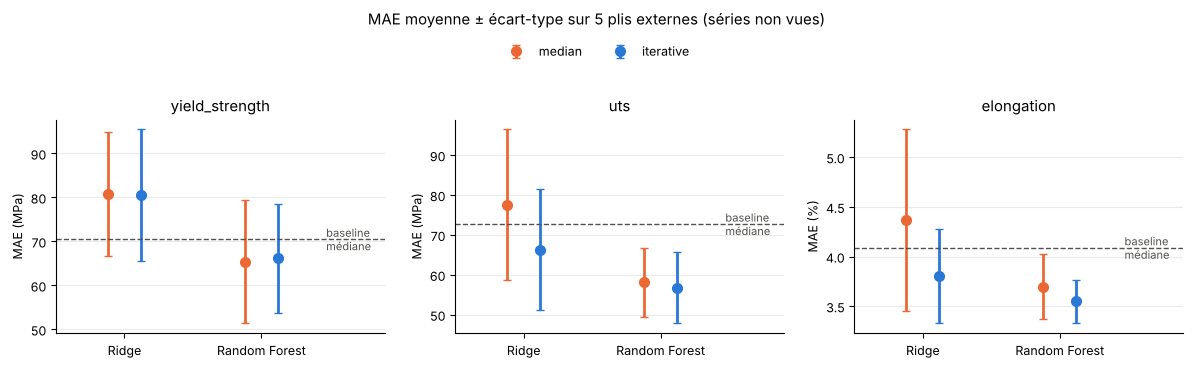

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
COL = {'median': '#eb6834', 'iterative': '#2a78d6'}
units = {'yield_strength': 'MPa', 'uts': 'MPa', 'elongation': '%'}
for ax, task in zip(axes, W.TENSILE):
    b = bench[bench.task == task]
    base = b[b.model == 'baseline_median'].MAE.mean()
    for j, model in enumerate(['ridge', 'rf']):
        for o, imp in [(-.12, 'median'), (.12, 'iterative')]:
            s = b[(b.model == model) & (b.imputer == imp)].MAE
            ax.errorbar(j + o, s.mean(), yerr=s.std(), fmt='o', ms=7, color=COL[imp], capsize=3, lw=2,
                        label=imp if (task == W.TENSILE[0] and j == 0) else None)
    ax.axhline(base, color='#52514e', ls='--', lw=1); ax.text(1.45, base, ' baseline\n médiane', va='center', color='#52514e', fontsize=8)
    ax.set_xticks([0, 1], ['Ridge', 'Random Forest']); ax.set_xlim(-.5, 1.9)
    ax.set_title(task); ax.set_ylabel(f'MAE ({units[task]})'); ax.grid(axis='x', visible=False)
fig.legend(loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(.5, 1.06))
fig.suptitle('MAE moyenne ± écart-type sur 5 plis externes (séries non vues)', y=1.13)
plt.tight_layout(); plt.show()

### Lecture

- L'itérative **converge** dans tous les plis (13 entrées) et n'est jamais nettement pire que la médiane.
- Avec **Ridge**, elle réduit l'erreur sur UTS et élongation : un modèle linéaire est sensible aux valeurs constantes injectées par la médiane.
- Avec **Random Forest**, l'écart est faible et dans la variabilité entre plis (sur la limite d'élasticité, la médiane est même légèrement devant dans 3 plis sur 5).
- Ridge à `alpha` fixe fait moins bien que la baseline sur la limite d'élasticité : un modèle linéaire non réglé extrapole mal vers des séries nouvelles.
- Les R² sont faibles sur des **séries non vues** : la généralisation à une nouvelle publication est difficile. C'est un résultat en soi, à garder pour le rapport, et ce n'est pas un problème d'imputation.

**Conclusion pour la décision :** rien ne justifie de remplacer l'itérative par la médiane sur l'espace 13 entrées. La reconstruction est meilleure, la convergence est vérifiée, et la prédiction est égale ou meilleure. La médiane reste la **baseline de sensibilité**, et le **repli documenté** si l'itérative ne converge pas dans un autre espace de features (ex. 21 entrées).

## 11. Exports et manifeste

`modeling/` contient uniquement des données **avant tout apprentissage** et les journaux :

| Fichier | Contenu |
|---|---|
| `master.csv` | 1 652 lignes brutes (y compris alias, non étiquetées, PWHT manquant), représentation principale, codes d'origine, drapeaux, groupes, éligibilités |
| `cell_provenance.csv` | une ligne par cellule numérique : token brut, statut, bornes, opérateur, annotation, drapeau, valeur principale |
| `duplicate_aliases.csv` | alias → enregistrement conservé |
| `groups.csv` | série, règle, groupe pour chaque `raw_row_id` |
| `folds.csv` | plis externes et internes par `raw_row_id` (après déduplication) |
| `unit_review_cells.csv` | cellules en quarantaine d'unité |
| `charpy_protocol_candidates.csv` | signatures de protocole par série (hypothèses) |
| `imputer_benchmark.csv` | contrôle médiane / itérative par pli |
| `manifest.json` | hashes SHA-256 (brut, code), versions, paramètres, comptes |

In [17]:
master.to_csv(f'{OUT}/master.csv', index=False)
prov.to_csv(f'{OUT}/cell_provenance.csv', index=False)
aliases.to_csv(f'{OUT}/duplicate_aliases.csv', index=False)
groups.to_csv(f'{OUT}/groups.csv', index=False)
folds.to_csv(f'{OUT}/folds.csv', index=False)
rev.to_csv(f'{OUT}/unit_review_cells.csv', index=False)
cp.to_csv(f'{OUT}/charpy_protocol_candidates.csv')
bench.to_csv(f'{OUT}/imputer_benchmark.csv', index=False)
manifest = {
    'raw_sha256': W.sha256(RAW), 'code_sha256': W.sha256('weld_prep.py'),
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'sklearn': sklearn.__version__},
    'seed': W.SEED, 'feature_sets': W.FEATURE_SETS, 'primary_set': W.PRIMARY_SET,
    'process_synonyms': W.PROCESS_SYNONYMS, 'merge_name_variants': W.MERGE_NAME_VARIANTS,
    'imputer': {'method': 'iterative', 'estimator': 'BayesianRidge', 'initial_strategy': 'median',
                'order': 'ascending', 'max_iter': 100, 'tol': 1e-3, 'lower_bound': 0, 'pwht_pair_projection': True},
    'folds': {'outer': 'GroupKFold(5), no shuffle', 'inner': 'GroupKFold(3) per outer train, no shuffle'},
    'counts': {'raw': len(master), 'after_dedup': len(dedup), 'groups': int(dedup.group.nunique()),
               'strict13_rows': int(dedup.in_strict13.sum()), 'strict13_groups': int(dedup.loc[dedup.in_strict13, 'group'].nunique()),
               'unit_review_cells': len(rev), 'unlabeled_all': int(dedup.is_unlabeled_all.sum())},
    'files': {fn: W.sha256(f'{OUT}/{fn}') for fn in sorted(os.listdir(OUT)) if fn.endswith('.csv')},
}
json.dump(manifest, open(f'{OUT}/manifest.json', 'w'), indent=2, ensure_ascii=False)
manifest['counts']

{'raw': 1652,
 'after_dedup': 1648,
 'groups': 47,
 'strict13_rows': 1555,
 'strict13_groups': 44,
 'unit_review_cells': 322,
 'unlabeled_all': 105}

## 12. Ce qui reste ouvert (non tranché ici)

- **Unités** : les 322 cellules en quarantaine ne pourront être restaurées qu'avec la page ou le tableau de la publication source (statut « confirmé » à ajouter dans `unit_review_cells.csv`).
- **Azote annoté** : comparabilité total / résiduel à établir avant de l'utiliser.
- **Charpy** : vérifier les signatures dans les publications, puis définir E(T) et T100J / T28J séparément.
- **Groupes** : séries dérivées des identifiants, pas des publications validées ; tester `MERGE_NAME_VARIANTS=True` en sensibilité.
- **Cohorte stricte (≤ 2 indisponibles)** : seuil d'ingénierie ; rapporter la sensibilité (ex. ≤ 1, ≤ 3) et les groupes perdus.
- **Imputation itérative sur 16 ou 21 entrées** : refaire le contrôle de convergence dans chaque pli final.
- **Semi-supervision** (COREG, inductive) : pool non étiqueté pris uniquement dans les groupes d'entraînement du pli.